# H2O AutoML aplicado a la serie de radiación solar — Pronóstico a 24 horas y a 1 semana (v3: pronóstico meteorológico + cielo despejado teórico)

Versión para ejecutar directamente, celda por celda, desde Jupyter Notebook o JupyterLab. No requiere SLURM.

## Evolución del notebook

| Versión | Qué predice el modelo | Qué información usa |
|---|---|---|
| v1 | Radiación en W/m² | Retardos, medias móviles, meteorología de la estación |
| v2 | Índice de claridad `kt = radiación / cielo despejado` (envolvente empírica) | + tendencias de presión y humedad, pesos por radiación, sólo horas diurnas |
| **v3** | Índice de claridad sobre **cielo despejado teórico** (`pvlib`) | **+ pronóstico meteorológico histórico (Open-Meteo)** de nubosidad y radiación para el instante objetivo |

## Novedades de la v3

1. **Pronóstico de nubosidad como variable exógena.** Se descargan de la *Previous Runs API* de Open-Meteo los valores que el modelo meteorológico **pronosticó con 1 día de anticipación** (para el horizonte de 24 h) y **con 7 días de anticipación** (para el horizonte de 1 semana): nubosidad total, baja, media y alta; radiación global, directa y difusa; temperatura, humedad y precipitación. Es la información que realmente se tendría disponible al momento de pronosticar. Además se incorpora el **pronóstico meteorológico crudo** como tercer modelo de referencia: el modelo H2O tiene que superarlo para justificar su uso.
2. **Cielo despejado teórico con `pvlib`** (modelo de Ineichen), calculado con la latitud, la longitud y la altitud de la estación. No depende de que haya habido días despejados en las semanas previas. Antes de usarlo se **calibra automáticamente**: se detecta si hay un desfase horario entre la estación y el sol (por ejemplo, si la estación registra en UTC) y se ajusta un factor de escala con los datos de entrenamiento.
3. **Dos modos de AutoML**: `'rapido'` para verificar que el flujo funciona y `'completo'` (1 hora por horizonte, hasta 60 modelos e incluye Deep Learning) para el resultado final.
4. **Evaluación honesta del horizonte de 1 semana**: se informa el *skill score* respecto de la climatología (`1 − RMSE_modelo / RMSE_climatología`). Si es positivo, el modelo le gana a la climatología.

Si no se indican coordenadas, o no hay conexión a Internet, el notebook sigue funcionando: vuelve a la envolvente empírica de la v2 y omite el pronóstico meteorológico, avisándolo en pantalla.

Los resultados se guardan en `resultados_h2o_radiacion_v3/` (misma estructura: `24h/` y `7d/`, cada una con `graficos/`, `metricas/` y `modelos/`).

## 1. Instalación de librerías
Ejecutar esta celda solamente si las librerías no están instaladas.

In [ ]:
%pip install -q h2o pandas numpy scikit-learn matplotlib seaborn pvlib requests

## 2. Carga de librerías

In [1]:
import os
import json
import math
import time
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import requests
import h2o
from h2o.automl import H2OAutoML
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

try:
    import pvlib
    PVLIB_DISPONIBLE = True
except ImportError:
    PVLIB_DISPONIBLE = False
    print('Aviso: pvlib no está instalado; se usará la envolvente empírica de cielo despejado.')

pd.set_option('display.max_columns', 50)
plt.style.use('seaborn-v0_8-whitegrid')

## 3. Configuración general

**Completar la ubicación de la estación.** Las coordenadas se usan para el cielo despejado teórico y para descargar el pronóstico meteorológico del punto correcto.

- `LATITUD` y `LONGITUD` en grados decimales (en Argentina ambas son negativas; por ejemplo, Córdoba capital ≈ −31,42 / −64,19).
- `ALTITUD` en metros sobre el nivel del mar (mejora el cálculo de cielo despejado; si no se conoce, dejar un valor aproximado).
- `ZONA_HORARIA`: la zona horaria **en la que están registradas las fechas del archivo**. Si la estación registra en UTC, poner `'UTC'`. De todos modos, la calibración de la sección 9 detecta y corrige desfases.

In [2]:
# --- Ubicación de la estación (COMPLETAR) --- -28.454096853029977, -65.76365956212574
LATITUD = -28.454096853029977        # ej.: -31.42
LONGITUD = -65.76365956212574       # ej.: -64.19
ALTITUD = 550           # metros sobre el nivel del mar
ZONA_HORARIA = 'America/Argentina/Buenos_Aires'

# --- Mejoras activables ---
USAR_CIELO_TEORICO = True    # cielo despejado con pvlib (requiere coordenadas)
USAR_PRONOSTICO_NWP = True   # pronóstico meteorológico histórico de Open-Meteo (requiere coordenadas e Internet)
MODELO_NWP = 'best_match'    # modelo meteorológico de Open-Meteo: 'best_match', 'ecmwf_ifs025', 'gfs_seamless', ...
MARGEN_DIAS_NWP = 0          # 0: usa el pronóstico emitido h días antes; 1: uno más antiguo (más conservador)
RECORTAR_A_COBERTURA_NWP = True  # entrena sólo en el período con pronóstico disponible (Open-Meteo archiva desde 2024)

# --- AutoML ---
MODO_AUTOML = 'rapido'       # 'rapido' para probar el flujo; 'completo' para el resultado final
CONFIG_AUTOML = {
    'rapido':   dict(max_runtime_secs=600,  max_models=15, exclude_algos=['DeepLearning']),
    'completo': dict(max_runtime_secs=3600, max_models=60, exclude_algos=[]),
}

# --- Parámetros del índice de claridad ---
PASOS_DIA = 96
UMBRAL_DIURNO = 20   # W/m²: con cielo despejado menor a esto se considera noche y se pronostica 0
KT_MAX = 1.3         # tope del índice de claridad (permite el realce por nubes)

COORDENADAS_OK = LATITUD is not None and LONGITUD is not None
if not COORDENADAS_OK:
    print('Aviso: no se indicaron LATITUD/LONGITUD. Se usará la envolvente empírica y no se descargará pronóstico meteorológico.')
USAR_CIELO_TEORICO = USAR_CIELO_TEORICO and COORDENADAS_OK and PVLIB_DISPONIBLE
USAR_PRONOSTICO_NWP = USAR_PRONOSTICO_NWP and COORDENADAS_OK
print('Cielo despejado teórico:', USAR_CIELO_TEORICO, '| Pronóstico NWP:', USAR_PRONOSTICO_NWP, '| Modo AutoML:', MODO_AUTOML)

Cielo despejado teórico: True | Pronóstico NWP: True | Modo AutoML: rapido


## 4. Carga de la base de radiación

In [3]:
RUTA_DATOS = 'unificada.csv'  # Cambiar si el archivo está en otra carpeta
df = pd.read_csv(RUTA_DATOS, sep=';', low_memory=False)
df.head()

,fecha,temperatura,humedad,presion,radiacion,precipitacion,precipitacion_acum_diaria,veloc_de_viento_max_10m,veloc_de_viento_min_10m,veloc_de_viento_prom_10m,direccion_de_viento_a_10m,direccion_a_10m,veloc_de_viento_max_2m,veloc_de_viento_min_2m,veloc_de_viento_prom_2m,direccion_de_viento_a_2m,direccion_a_2m,evaporimetro,evaporacion_acum_diaria
0,18/8/2016 01:00,NaN,24.2,954.5,0.0,0.0,0.0,0.0,0.0,0.0,NaN,NaN,0.0,0.0,0.0,NaN,NaN,NaN,NaN
1,18/8/2016 01:15,18.9,24.0,954.5,0.0,0.0,0.0,44.8,0.0,26.7,13.3,NaN,33.1,0.0,17.7,23.6,NaN,NaN,NaN
2,18/8/2016 01:30,19.0,23.6,954.5,0.0,0.0,0.0,46.6,0.0,27.5,14.2,NaN,30.4,0.0,17.7,23.6,NaN,NaN,NaN
3,18/8/2016 01:45,19.1,23.4,954.5,0.0,0.0,0.0,49.3,0.0,28.1,12.2,NaN,34.9,0.0,18.4,20.8,NaN,NaN,NaN
4,18/8/2016 02:00,19.0,23.4,954.5,0.0,0.0,0.0,42.1,0.0,26.1,15.2,NaN,29.5,0.0,17.3,23.2,NaN,NaN,NaN


## 5. Análisis exploratorio general

In [4]:
print('Dimensión:', df.shape)
df.info()

Dimensión: (336767, 19)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 336767 entries, 0 to 336766
Data columns (total 19 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   fecha                      336767 non-null  object 
 1   temperatura                336642 non-null  float64
 2   humedad                    336666 non-null  float64
 3   presion                    335006 non-null  float64
 4   radiacion                  336702 non-null  object 
 5   precipitacion              336728 non-null  float64
 6   precipitacion_acum_diaria  335911 non-null  float64
 7   veloc_de_viento_max_10m    336767 non-null  float64
 8   veloc_de_viento_min_10m    336767 non-null  float64
 9   veloc_de_viento_prom_10m   336767 non-null  float64
 10  direccion_de_viento_a_10m  336610 non-null  float64
 11  direccion_a_10m            290846 non-null  object 
 12  veloc_de_viento_max_2m     336767 non-null  object 
 13  veloc

In [5]:
# Conversión de fecha y columnas numéricas
df['fecha'] = pd.to_datetime(df['fecha'], dayfirst=True, errors='coerce')
variables = [
    'radiacion', 'temperatura', 'humedad', 'presion', 'precipitacion',
    'precipitacion_acum_diaria', 'veloc_de_viento_prom_10m',
    'veloc_de_viento_prom_2m'
]
variables = [c for c in variables if c in df.columns]
for c in variables:
    df[c] = pd.to_numeric(df[c].astype(str).str.replace(',', '.', regex=False), errors='coerce')

df = (df.dropna(subset=['fecha'])
        .sort_values('fecha')
        .drop_duplicates('fecha', keep='last')
        .set_index('fecha'))
df[variables].describe().T

,count,mean,std,min,25%,50%,75%,max
radiacion,336464.0,192.934876,278.726192,0.0,0.0,1.5,360.6,999.8
temperatura,336639.0,21.510030,7.905230,-38.3,16.1,22.0,27.3,44.8
humedad,336663.0,49.399627,20.569982,1.0,32.6,47.9,63.9,100.0
presion,335003.0,951.621044,12.233353,25.3,947.8,951.6,955.8,974.6
precipitacion,336725.0,0.013428,0.270754,0.0,0.0,0.0,0.0,90.7
precipitacion_acum_diaria,335908.0,0.708566,4.069848,0.0,0.0,0.0,0.0,90.7
veloc_de_viento_prom_10m,336764.0,11.559930,8.957427,0.0,4.0,9.9,18.3,61.4
veloc_de_viento_prom_2m,336764.0,7.335422,6.521024,0.0,1.0,6.1,12.1,44.3


In [6]:
calidad = pd.DataFrame({
    'tipo': df[variables].dtypes.astype(str),
    'faltantes': df[variables].isna().sum(),
    'porcentaje_faltante': df[variables].isna().mean().mul(100).round(2)
})
calidad

,tipo,faltantes,porcentaje_faltante
radiacion,float64,300,0.09
temperatura,float64,125,0.04
humedad,float64,101,0.03
presion,float64,1761,0.52
precipitacion,float64,39,0.01
precipitacion_acum_diaria,float64,856,0.25
veloc_de_viento_prom_10m,float64,0,0.00
veloc_de_viento_prom_2m,float64,0,0.00


## 6. Visualización de la radiación y las variables meteorológicas

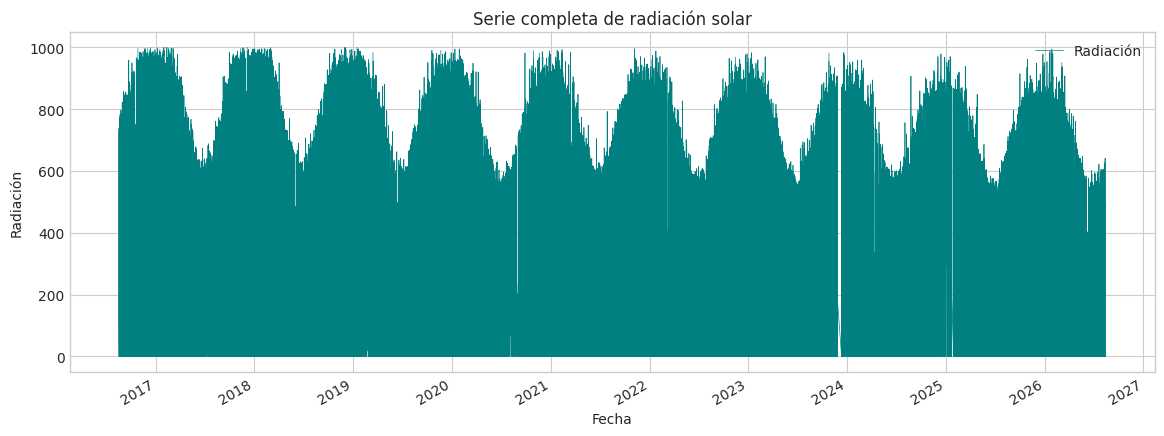

In [7]:
ax = df['radiacion'].plot(label='Radiación', color='teal', figsize=(14, 5), lw=0.5)
ax.set(title='Serie completa de radiación solar', xlabel='Fecha', ylabel='Radiación')
plt.legend();
plt.show()

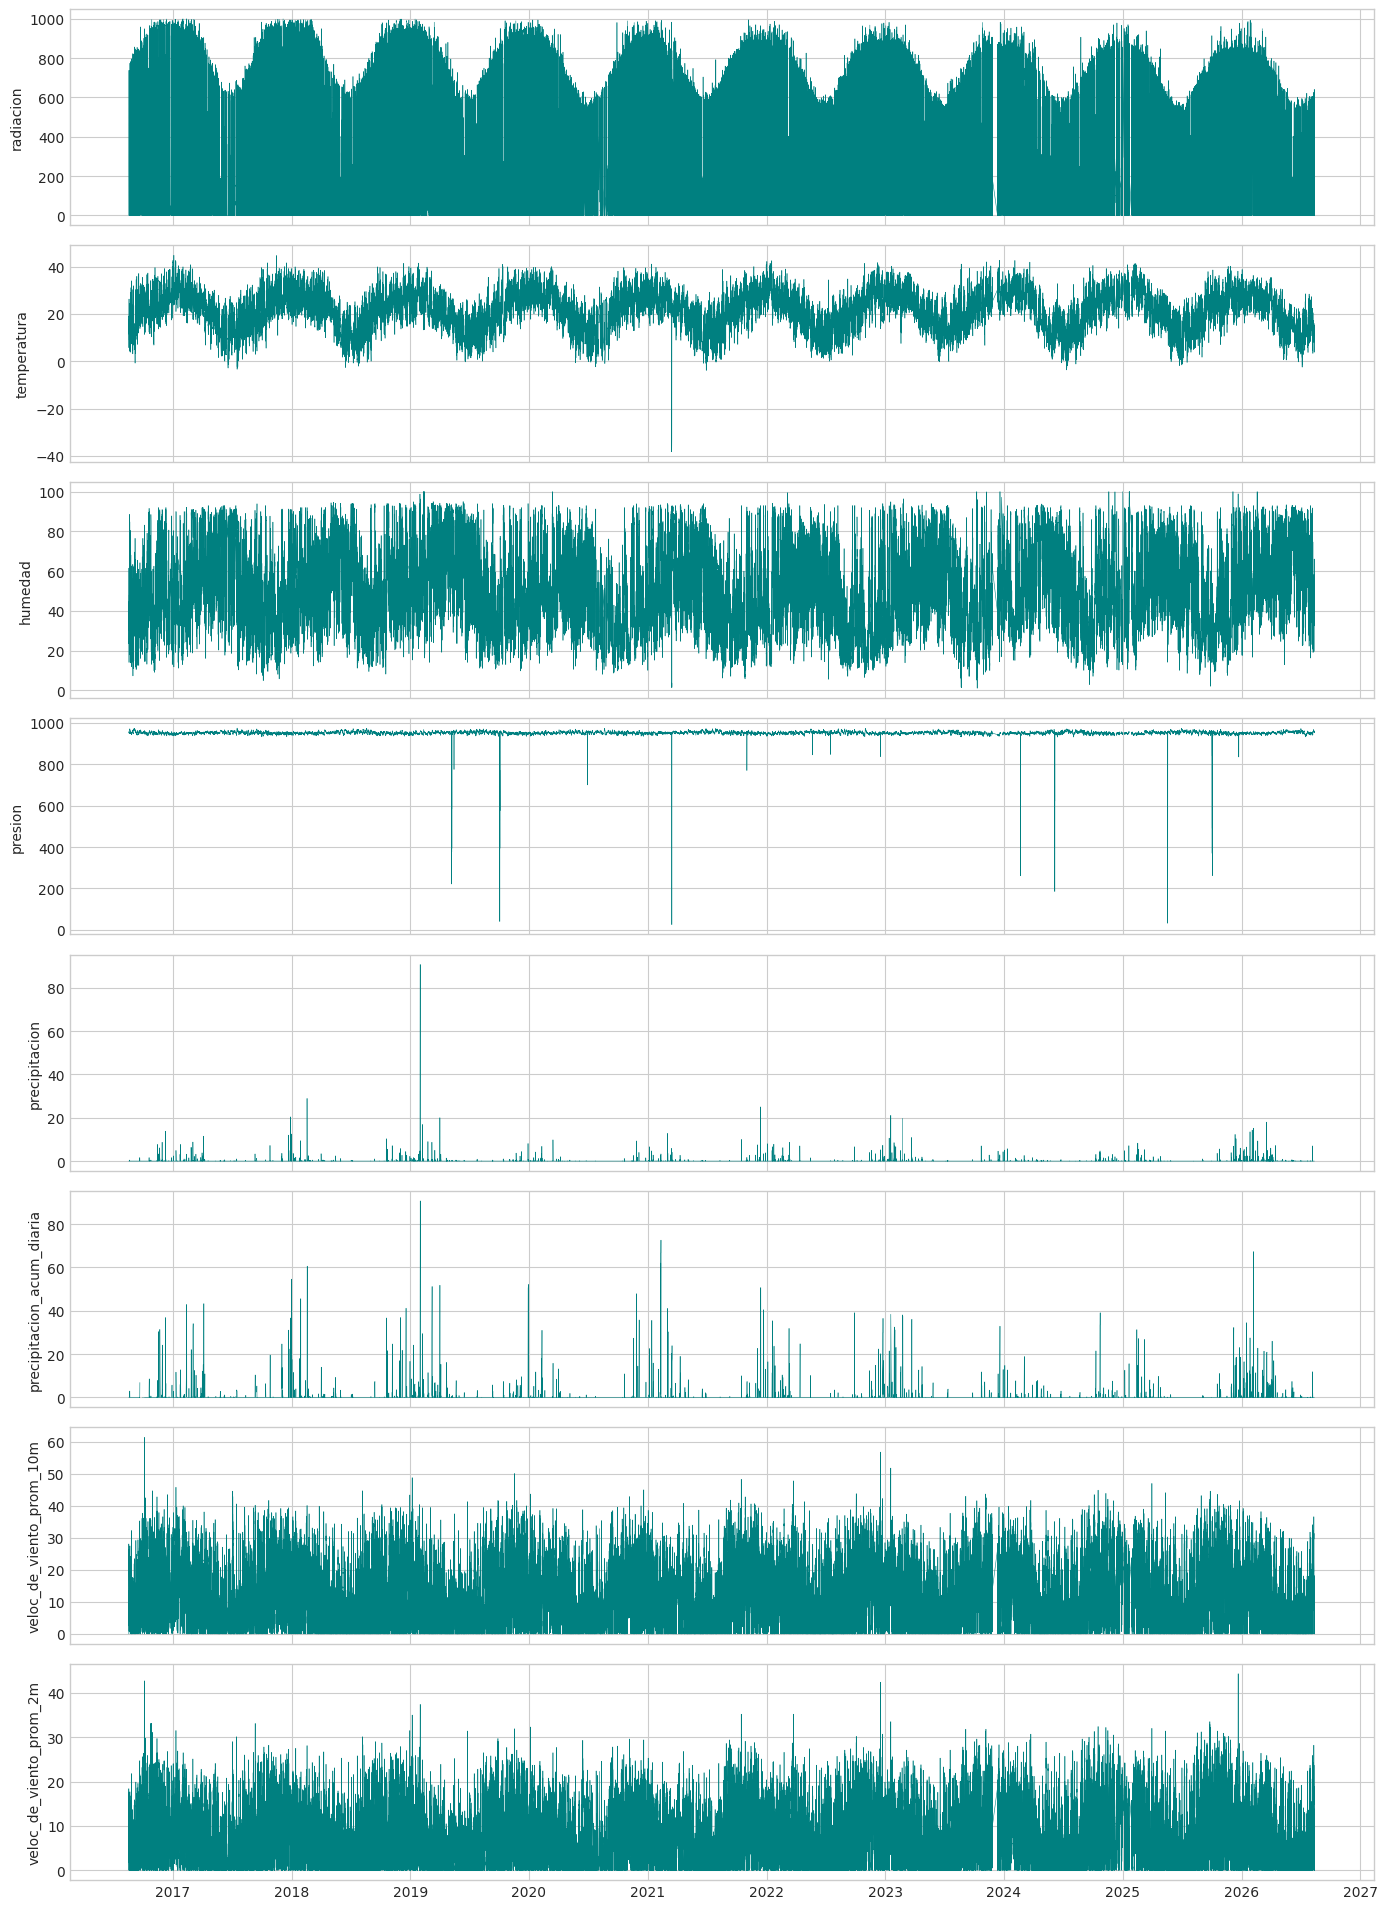

In [8]:
columnas_grafico = [c for c in variables if c in df.columns]
fig, axes = plt.subplots(len(columnas_grafico), 1, figsize=(14, 2.4*len(columnas_grafico)), sharex=True)
for ax, c in zip(np.atleast_1d(axes), columnas_grafico):
    ax.plot(df.index, df[c], color='teal', lw=0.4)
    ax.set_ylabel(c)
plt.tight_layout();
plt.show()

## 7. Matriz de correlación

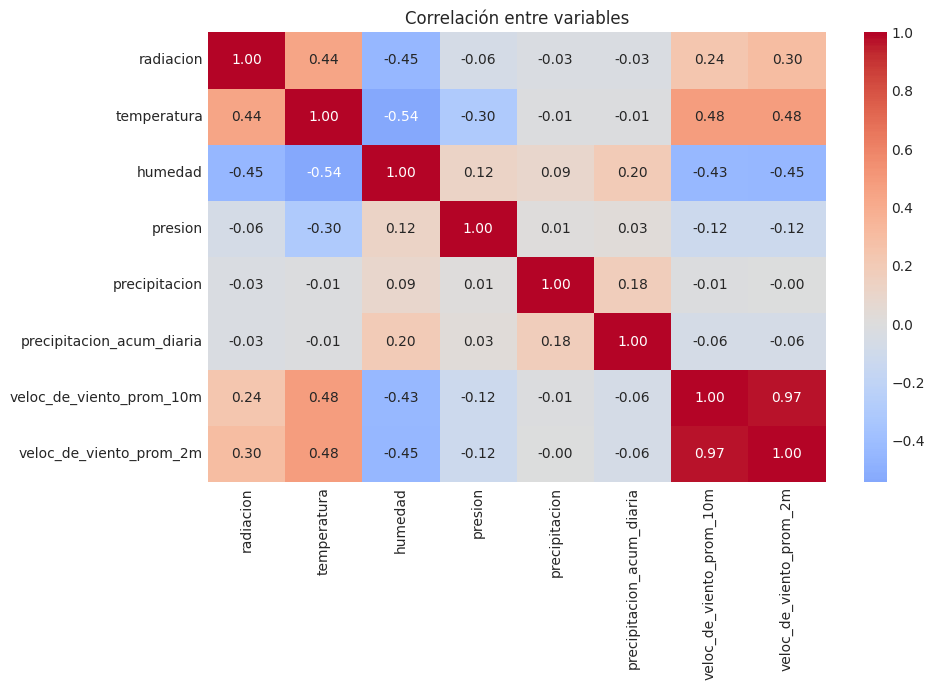

In [9]:
plt.figure(figsize=(10, 7))
sns.heatmap(df[variables].corr(), cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Correlación entre variables')
plt.tight_layout();
plt.show()

## 8. Regularización de la frecuencia
Se reconstruye la frecuencia exacta de 15 minutos para que los retardos y los horizontes de pronóstico representen siempre el mismo intervalo de tiempo real.

In [10]:
df_modelo = df[variables].copy()
indice_regular = pd.date_range(df_modelo.index.min(), df_modelo.index.max(), freq='15min')
df_modelo = df_modelo.reindex(indice_regular)
df_modelo.index.name = 'fecha'

exogenas = [c for c in variables if c != 'radiacion']
df_modelo[exogenas] = df_modelo[exogenas].interpolate(
    method='time', limit=4, limit_direction='both'
)
df_modelo.loc[df_modelo['radiacion'] < 0, 'radiacion'] = np.nan
print('Período:', df_modelo.index.min(), 'a', df_modelo.index.max())
print('Filas regulares:', len(df_modelo))

Período: 2016-08-18 01:00:00 a 2026-08-12 22:15:00
Filas regulares: 350102


## 9. Cielo despejado: teórico (`pvlib`) con calibración, o envolvente empírica

**Teórico.** Se calcula la radiación global de cielo despejado (modelo de Ineichen) para cada instante, incluso a futuro. Luego se calibra con el **70 % inicial de los datos** (el mismo tramo que se usará para entrenar, así no se filtra información del período de prueba):

- **Desfase horario:** se prueba correr la curva teórica entre −4 h y +4 h, en pasos de 15 minutos, y se elige el desfase de mayor correlación con la radiación observada. Un desfase de ±7,5 a 15 min es normal (los registros suelen ser promedios del intervalo); uno de 3 h indica que la estación registra en UTC.
- **Factor de escala:** cuantil 0,95 del cociente radiación observada / cielo teórico al mediodía. Corrige diferencias de calibración del sensor o de turbidez local.

**Empírica (respaldo).** Si no hay coordenadas o `pvlib`, se usa la envolvente de la v2: cuantil 0,95 de la radiación en el mismo horario de los 14 días previos.

Desfase detectado: +0 minutos (correlación 0.885)
Factor de escala: 0.989


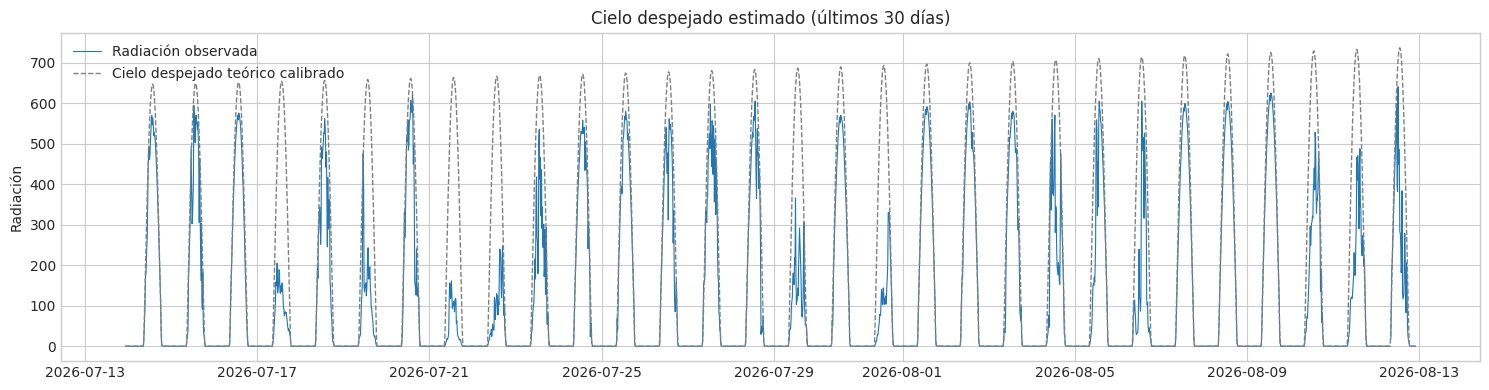

In [11]:
DIAS_ENVOLVENTE = 14
CUANTIL_ENVOLVENTE = 0.95
PASOS_EXTRA = 672 + 2 * PASOS_DIA   # se extiende la grilla para poder consultar t + 1 semana

grilla_ext = pd.date_range(df_modelo.index.min() - pd.Timedelta(days=1),
                           df_modelo.index.max() + pd.Timedelta(minutes=15 * PASOS_EXTRA), freq='15min')
n_calibracion = int(len(df_modelo) * 0.70)
rad_calibracion = df_modelo['radiacion'].iloc[:n_calibracion]
DESFASE_PASOS = 0


def envolvente_cielo_despejado(rad, horizonte_pasos):
    """Envolvente empírica (v2): cielo despejado para t + h a partir de días previos, sólo con datos conocidos en t."""
    k0 = max(1, math.ceil(horizonte_pasos / PASOS_DIA))
    desfases = [PASOS_DIA * k - horizonte_pasos for k in range(k0, k0 + DIAS_ENVOLVENTE)]
    matriz = np.column_stack([rad.shift(d).to_numpy() for d in desfases])
    validos = np.sum(~np.isnan(matriz), axis=1)
    with warnings.catch_warnings():
        warnings.simplefilter('ignore', category=RuntimeWarning)
        env = np.nanquantile(matriz, CUANTIL_ENVOLVENTE, axis=1)
    env[validos < DIAS_ENVOLVENTE // 2] = np.nan
    return pd.Series(env, index=rad.index)


if USAR_CIELO_TEORICO:
    ubicacion = pvlib.location.Location(LATITUD, LONGITUD, tz=ZONA_HORARIA, altitude=ALTITUD)
    grilla_tz = grilla_ext.tz_localize(ZONA_HORARIA, nonexistent='shift_forward', ambiguous='NaT')
    try:
        cs_crudo = ubicacion.get_clearsky(grilla_tz, model='ineichen')['ghi']
    except Exception as e:
        print('Ineichen no disponible, se usa Haurwitz:', e)
        cs_crudo = ubicacion.get_clearsky(grilla_tz, model='haurwitz')['ghi']
    cs_crudo = pd.Series(cs_crudo.to_numpy(), index=grilla_ext)
    elevacion_cruda = pd.Series(ubicacion.get_solarposition(grilla_tz)['apparent_elevation'].to_numpy(), index=grilla_ext)

    # --- Desfase horario ---
    correlaciones = {}
    for s in range(-16, 17):
        correlaciones[s] = rad_calibracion.corr(cs_crudo.shift(s).reindex(rad_calibracion.index))
    DESFASE_PASOS = max(correlaciones, key=correlaciones.get)
    print(f'Desfase detectado: {DESFASE_PASOS * 15:+d} minutos (correlación {correlaciones[DESFASE_PASOS]:.3f})')
    if abs(DESFASE_PASOS) >= 4:
        print('  ATENCIÓN: desfase de 1 hora o más. Revisar ZONA_HORARIA (¿la estación registra en UTC?). Se corrige automáticamente.')
    cs_alineado = cs_crudo.shift(DESFASE_PASOS)
    elevacion_solar = elevacion_cruda.shift(DESFASE_PASOS)

    # --- Factor de escala ---
    cs_cal = cs_alineado.reindex(rad_calibracion.index)
    mediodia = cs_cal > 300
    FACTOR_ESCALA = float(np.nanquantile(rad_calibracion[mediodia] / cs_cal[mediodia], 0.95))
    print(f'Factor de escala: {FACTOR_ESCALA:.3f}')
    if not 0.7 <= FACTOR_ESCALA <= 1.3:
        print('  ATENCIÓN: factor lejos de 1. Revisar unidades de la radiación (¿W/m²?) o las coordenadas.')
    cielo_teorico = cs_alineado * FACTOR_ESCALA
else:
    print('Se usa la envolvente empírica de cielo despejado (v2).')


def cielo_para_horizonte(horizonte_pasos):
    """Serie indexada por t con el cielo despejado estimado para el instante t + horizonte_pasos."""
    if USAR_CIELO_TEORICO:
        destino = df_modelo.index + pd.Timedelta(minutes=15 * horizonte_pasos)
        return pd.Series(cielo_teorico.reindex(destino).to_numpy(), index=df_modelo.index)
    return envolvente_cielo_despejado(df_modelo['radiacion'], horizonte_pasos)


# --- Gráfico de control: últimos 30 días ---
_cs = cielo_para_horizonte(0)
_ult = df_modelo.index >= df_modelo.index.max() - pd.Timedelta(days=30)
plt.figure(figsize=(15, 4))
plt.plot(df_modelo.index[_ult], df_modelo['radiacion'][_ult], lw=0.8, label='Radiación observada')
plt.plot(df_modelo.index[_ult], _cs[_ult], '--', color='gray', lw=1,
         label='Cielo despejado ' + ('teórico calibrado' if USAR_CIELO_TEORICO else 'empírico'))
plt.title('Cielo despejado estimado (últimos 30 días)')
plt.ylabel('Radiación'); plt.legend(); plt.tight_layout(); plt.show()

## 10. Pronóstico meteorológico histórico (Open-Meteo, *Previous Runs API*)

Para entrenar con un pronóstico meteorológico hay que usar **lo que el modelo meteorológico pronosticaba en su momento**, no lo que ocurrió después (eso sería hacer trampa). La *Previous Runs API* de Open-Meteo guarda justamente eso: la variable `shortwave_radiation_previous_day1` es la radiación que se pronosticó **24 h antes**, y `..._previous_day7`, **7 días antes**.

- Horizonte 24 h → pronóstico con 1 día de anticipación.
- Horizonte 1 semana → pronóstico con 7 días de anticipación.
- Los datos están archivados desde **enero de 2024** para la mayoría de los modelos. Si la serie de la estación empieza antes, esas filas no tendrán pronóstico (ver `RECORTAR_A_COBERTURA_NWP`).
- Los datos son horarios; se interpolan a 15 minutos. Las variables de radiación de Open-Meteo son el promedio de la hora anterior, por eso se centran 30 minutos antes de interpolar.
- La descarga se guarda en `pronostico_openmeteo_previous_dayN.csv`: la próxima ejecución lee el archivo y no vuelve a descargar. **Borrar ese archivo para forzar una nueva descarga** (por ejemplo, si se cambian las coordenadas o el modelo).
- Uso gratuito y no comercial de Open-Meteo; para uso comercial requiere clave de API.

> Nota sobre anticipación real: un pronóstico "de 24 h antes" suele publicarse unas horas después de su hora de inicio. Para una evaluación estrictamente conservadora, poner `MARGEN_DIAS_NWP = 1` (usa el pronóstico de 48 h antes para el horizonte de 24 h).

In [12]:
URL_NWP = 'https://previous-runs-api.open-meteo.com/v1/forecast'
INICIO_ARCHIVO_NWP = pd.Timestamp('2024-01-01')
VARIABLES_NWP = {
    'shortwave_radiation': 'nwp_ghi',
    'direct_radiation': 'nwp_directa',
    'diffuse_radiation': 'nwp_difusa',
    'cloud_cover': 'nwp_nubosidad',
    'cloud_cover_low': 'nwp_nubosidad_baja',
    'cloud_cover_mid': 'nwp_nubosidad_media',
    'cloud_cover_high': 'nwp_nubosidad_alta',
    'temperature_2m': 'nwp_temperatura',
    'relative_humidity_2m': 'nwp_humedad',
    'precipitation': 'nwp_precipitacion',
}
VARIABLES_RADIACION_NWP = ['nwp_ghi', 'nwp_directa', 'nwp_difusa']


def _pedir_open_meteo(variables, dias, desde, hasta):
    params = {
        'latitude': LATITUD, 'longitude': LONGITUD,
        'hourly': ','.join(f'{v}_previous_day{dias}' for v in variables),
        'start_date': desde.strftime('%Y-%m-%d'), 'end_date': hasta.strftime('%Y-%m-%d'),
        'timezone': ZONA_HORARIA, 'models': MODELO_NWP,
    }
    for intento in range(3):
        r = requests.get(URL_NWP, params=params, timeout=180)
        if r.status_code == 200:
            return pd.DataFrame(r.json()['hourly'])
        if r.status_code == 429:           # límite de consultas: esperar y reintentar
            time.sleep(60)
            continue
        raise RuntimeError(f'HTTP {r.status_code}: {r.text[:300]}')
    raise RuntimeError('Se superó el límite de consultas de Open-Meteo; reintentar más tarde.')


def descargar_pronostico_nwp(dias):
    """Devuelve un DataFrame horario con el pronóstico emitido `dias` días antes (columnas nwp_*)."""
    ruta = f'pronostico_openmeteo_previous_day{dias}.csv'
    if os.path.exists(ruta):
        print(f'Leyendo pronóstico guardado: {ruta}')
        return pd.read_csv(ruta, parse_dates=['fecha'], index_col='fecha')

    desde = max(df_modelo.index.min().normalize(), INICIO_ARCHIVO_NWP)
    hasta = min(df_modelo.index.max().normalize() + pd.Timedelta(days=dias + 1), pd.Timestamp.today().normalize())
    variables_ok = list(VARIABLES_NWP)
    partes = []
    for inicio in pd.date_range(desde, hasta, freq='90D'):
        fin = min(inicio + pd.Timedelta(days=89), hasta)
        print(f'Descargando previous_day{dias}: {inicio.date()} a {fin.date()}')
        try:
            parte = _pedir_open_meteo(variables_ok, dias, inicio, fin)
        except RuntimeError as e:
            # Si alguna variable no está disponible para el modelo elegido, se prueban de a una
            print('  Consulta conjunta falló, se prueban las variables de a una:', e)
            parte, sobrevivientes = None, []
            for v in variables_ok:
                try:
                    p = _pedir_open_meteo([v], dias, inicio, fin)
                    parte = p if parte is None else parte.merge(p, on='time', how='outer')
                    sobrevivientes.append(v)
                except RuntimeError as e2:
                    print(f'  Variable descartada: {v} ({e2})')
            variables_ok = sobrevivientes
            if parte is None:
                continue
        partes.append(parte)
        time.sleep(1)

    if not partes:
        raise RuntimeError('No se pudo descargar ningún dato de pronóstico.')
    nwp = pd.concat(partes, ignore_index=True)
    nwp['fecha'] = pd.to_datetime(nwp.pop('time'))
    nwp = nwp.drop_duplicates('fecha').set_index('fecha').sort_index()
    nwp.columns = [VARIABLES_NWP[c.replace(f'_previous_day{dias}', '')] for c in nwp.columns]
    nwp = nwp.dropna(how='all')
    nwp.to_csv(ruta)
    print(f'Pronóstico guardado en {ruta}: {nwp.shape}')
    return nwp


def pronostico_a_15min(nwp_horario):
    """Interpola a la grilla de 15 min y aplica el mismo desfase horario detectado para la estación."""
    salida = []
    for c in nwp_horario.columns:
        serie = nwp_horario[c].dropna()
        if c in VARIABLES_RADIACION_NWP:
            serie.index = serie.index - pd.Timedelta(minutes=30)   # promedio de la hora anterior -> centro del intervalo
        union = serie.index.union(grilla_ext)
        serie = serie.reindex(union).interpolate(method='time', limit=8, limit_area='inside').reindex(grilla_ext)
        if c in VARIABLES_RADIACION_NWP:
            serie = serie.clip(lower=0)
        salida.append(serie.rename(c))
    return pd.concat(salida, axis=1).shift(DESFASE_PASOS)


PRONOSTICOS_NWP = {}   # clave: días de anticipación -> DataFrame a 15 min sobre grilla_ext
if USAR_PRONOSTICO_NWP:
    for dias in sorted({1 + MARGEN_DIAS_NWP, 7 + MARGEN_DIAS_NWP}):
        try:
            PRONOSTICOS_NWP[dias] = pronostico_a_15min(descargar_pronostico_nwp(dias))
            cobertura = PRONOSTICOS_NWP[dias]['nwp_ghi'].reindex(df_modelo.index).notna().mean() * 100
            print(f'previous_day{dias}: variables {list(PRONOSTICOS_NWP[dias].columns)} | cobertura sobre la serie: {cobertura:.1f} %')
        except Exception as e:
            print(f'No se pudo obtener el pronóstico previous_day{dias}: {e}')
    if not PRONOSTICOS_NWP:
        print('Se continúa sin pronóstico meteorológico.')
        USAR_PRONOSTICO_NWP = False

Descargando previous_day1: 2024-01-01 a 2024-03-30
Descargando previous_day1: 2024-03-31 a 2024-06-28
Descargando previous_day1: 2024-06-29 a 2024-09-26
Descargando previous_day1: 2024-09-27 a 2024-12-25
Descargando previous_day1: 2024-12-26 a 2025-03-25
Descargando previous_day1: 2025-03-26 a 2025-06-23
Descargando previous_day1: 2025-06-24 a 2025-09-21
Descargando previous_day1: 2025-09-22 a 2025-12-20
Descargando previous_day1: 2025-12-21 a 2026-03-20
Descargando previous_day1: 2026-03-21 a 2026-06-18
Descargando previous_day1: 2026-06-19 a 2026-08-14
Pronóstico guardado en pronostico_openmeteo_previous_day1.csv: (22527, 10)


/tmp/ipykernel_3837372/2145941247.py:89: FutureWarning: Series.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  serie = serie.reindex(union).interpolate(method='time', limit=8, limit_area='inside').reindex(grilla_ext)


previous_day1: variables ['nwp_ghi', 'nwp_directa', 'nwp_difusa', 'nwp_nubosidad', 'nwp_nubosidad_baja', 'nwp_nubosidad_media', 'nwp_nubosidad_alta', 'nwp_temperatura', 'nwp_humedad', 'nwp_precipitacion'] | cobertura sobre la serie: 25.7 %
Descargando previous_day7: 2024-01-01 a 2024-03-30
Descargando previous_day7: 2024-03-31 a 2024-06-28
Descargando previous_day7: 2024-06-29 a 2024-09-26
Descargando previous_day7: 2024-09-27 a 2024-12-25
Descargando previous_day7: 2024-12-26 a 2025-03-25
Descargando previous_day7: 2025-03-26 a 2025-06-23
Descargando previous_day7: 2025-06-24 a 2025-09-21
Descargando previous_day7: 2025-09-22 a 2025-12-20
Descargando previous_day7: 2025-12-21 a 2026-03-20
Descargando previous_day7: 2026-03-21 a 2026-06-18
Descargando previous_day7: 2026-06-19 a 2026-08-20
Pronóstico guardado en pronostico_openmeteo_previous_day7.csv: (22527, 10)


/tmp/ipykernel_3837372/2145941247.py:89: FutureWarning: Series.interpolate with object dtype is deprecated and will raise in a future version. Call obj.infer_objects(copy=False) before interpolating instead.
  serie = serie.reindex(union).interpolate(method='time', limit=8, limit_area='inside').reindex(grilla_ext)


previous_day7: variables ['nwp_ghi', 'nwp_directa', 'nwp_difusa', 'nwp_nubosidad', 'nwp_nubosidad_baja', 'nwp_nubosidad_media', 'nwp_nubosidad_alta', 'nwp_temperatura', 'nwp_humedad', 'nwp_precipitacion'] | cobertura sobre la serie: 25.5 %


### 10.1 Control de calidad del pronóstico meteorológico

Antes de usarlo, conviene ver qué tan bien el pronóstico con 1 día de anticipación acompaña a la radiación medida. Si las curvas están corridas en el tiempo, revisar `ZONA_HORARIA`.

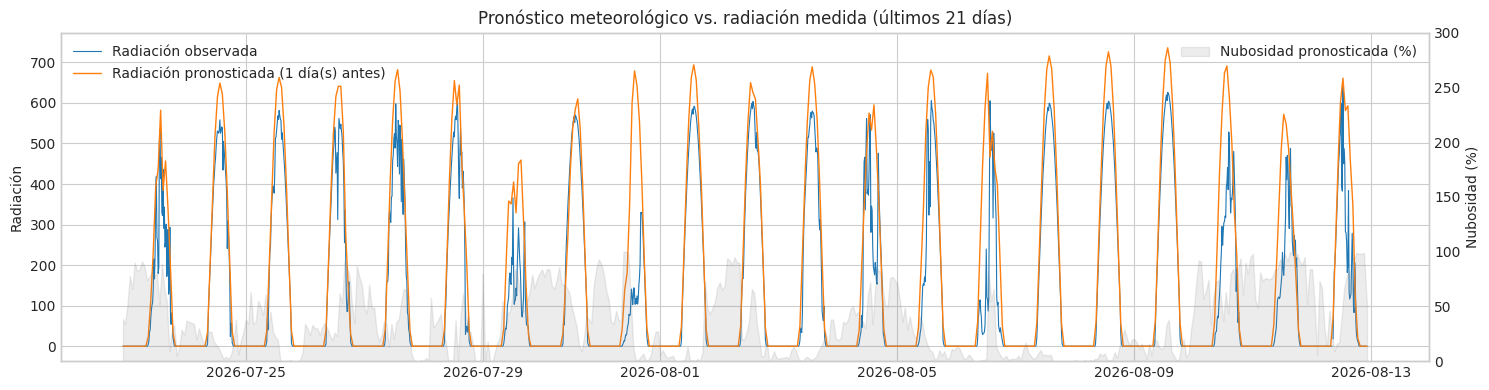

Correlación radiación medida vs. pronosticada: 0.945


In [13]:
if USAR_PRONOSTICO_NWP and PRONOSTICOS_NWP:
    dias_ctrl = min(PRONOSTICOS_NWP)
    nwp_ctrl = PRONOSTICOS_NWP[dias_ctrl].reindex(df_modelo.index)
    _ult = df_modelo.index >= df_modelo.index.max() - pd.Timedelta(days=21)
    fig, ax1 = plt.subplots(figsize=(15, 4))
    ax1.plot(df_modelo.index[_ult], df_modelo['radiacion'][_ult], lw=0.8, label='Radiación observada')
    ax1.plot(df_modelo.index[_ult], nwp_ctrl['nwp_ghi'][_ult], lw=1, label=f'Radiación pronosticada ({dias_ctrl} día(s) antes)')
    ax1.set_ylabel('Radiación'); ax1.legend(loc='upper left')
    if 'nwp_nubosidad' in nwp_ctrl:
        ax2 = ax1.twinx()
        ax2.fill_between(df_modelo.index[_ult], nwp_ctrl['nwp_nubosidad'][_ult], color='gray', alpha=0.15, label='Nubosidad pronosticada (%)')
        ax2.set_ylim(0, 300); ax2.set_ylabel('Nubosidad (%)'); ax2.legend(loc='upper right'); ax2.grid(False)
    plt.title('Pronóstico meteorológico vs. radiación medida (últimos 21 días)')
    plt.tight_layout(); plt.show()

    comun = nwp_ctrl['nwp_ghi'].notna() & df_modelo['radiacion'].notna()
    print('Correlación radiación medida vs. pronosticada:', round(df_modelo['radiacion'][comun].corr(nwp_ctrl['nwp_ghi'][comun]), 3))
else:
    print('Sin pronóstico meteorológico: se omite este control.')

## 11. Conversión de la serie temporal en aprendizaje supervisado (parametrizada por horizonte)

Todas las variables usan información disponible hasta el instante `t`. El pronóstico meteorológico entra **en el instante objetivo `t + h`** (es información conocida en `t`, porque fue emitido antes), junto con:

- el índice de claridad pronosticado (`nwp_kt` = radiación pronosticada / cielo despejado),
- la radiación pronosticada 1 hora antes y después del instante objetivo (tolera errores de horario de las nubes),
- el índice de claridad pronosticado **para el día completo** del instante objetivo.

In [14]:
def preparar_serie_supervisada(datos, horizonte_pasos, exogenas):
    rad = datos['radiacion']
    h = horizonte_pasos
    s = pd.DataFrame(index=datos.index)
    destino = s.index + pd.Timedelta(minutes=15 * h)

    # --- Cielo despejado (objetivo y actual) ---
    s['cielo_desp_objetivo'] = cielo_para_horizonte(h)
    cielo_t = cielo_para_horizonte(0)
    s['cielo_desp_t'] = cielo_t
    if USAR_CIELO_TEORICO:
        s['elevacion_solar_objetivo'] = elevacion_solar.reindex(destino).to_numpy()
    kt = (rad / cielo_t.where(cielo_t > UMBRAL_DIURNO)).clip(0, KT_MAX)

    # --- Radiación actual, retardos y estadísticos móviles ---
    s['radiacion_t'] = rad
    for lag in [1, 4, 96, 192, 672]:
        s[f'radiacion_lag_{lag}'] = rad.shift(lag)
    for ventana in [4, 12, 96]:
        minimo = max(2, ventana // 2)
        s[f'radiacion_media_{ventana}'] = rad.rolling(ventana, min_periods=minimo).mean()
        s[f'radiacion_std_{ventana}'] = rad.rolling(ventana, min_periods=minimo).std()
    s['radiacion_max_24h'] = rad.rolling(96, min_periods=48).max()

    # --- Radiación en el MISMO HORARIO que el objetivo, en los días previos disponibles ---
    k0 = max(1, math.ceil(h / PASOS_DIA))
    for j in range(3):
        s[f'rad_mismo_horario_d{j + 1}'] = rad.shift(PASOS_DIA * (k0 + j) - h)
    s['rad_mismo_horario_media_7d'] = pd.concat(
        [rad.shift(PASOS_DIA * (k0 + j) - h) for j in range(7)], axis=1).mean(axis=1)

    # --- Índice de claridad reciente ---
    s['kt_t'] = kt
    for ventana in [4, 12, 96, 288]:
        s[f'kt_media_{ventana}'] = kt.rolling(ventana, min_periods=1).mean()
    s['kt_std_96'] = kt.rolling(96, min_periods=8).std()
    s['energia_24h_relativa'] = (rad.rolling(96, min_periods=48).sum()
                                 / cielo_t.rolling(96, min_periods=48).sum())

    # --- Meteorología de la estación y tendencias ---
    for c in exogenas:
        s[f'{c}_t'] = datos[c]
        s[f'{c}_lag_1'] = datos[c].shift(1)
    for c in ['presion', 'humedad', 'temperatura']:
        if c in exogenas:
            s[f'{c}_dif_3h'] = datos[c].diff(12)
            s[f'{c}_dif_24h'] = datos[c].diff(96)
    if 'temperatura' in exogenas:
        s['amplitud_termica_24h'] = (datos['temperatura'].rolling(96, min_periods=48).max()
                                     - datos['temperatura'].rolling(96, min_periods=48).min())
    if 'humedad' in exogenas:
        s['humedad_media_24h'] = datos['humedad'].rolling(96, min_periods=48).mean()
    if 'precipitacion' in exogenas:
        s['precipitacion_24h'] = datos['precipitacion'].rolling(96, min_periods=48).sum()

    # --- Pronóstico meteorológico para el instante objetivo ---
    dias_nwp = math.ceil(h / PASOS_DIA) + MARGEN_DIAS_NWP
    if USAR_PRONOSTICO_NWP and dias_nwp in PRONOSTICOS_NWP:
        nwp = PRONOSTICOS_NWP[dias_nwp]
        for c in nwp.columns:
            s[c] = nwp[c].reindex(destino).to_numpy()
        s['nwp_ghi_menos_1h'] = nwp['nwp_ghi'].reindex(destino - pd.Timedelta(hours=1)).to_numpy()
        s['nwp_ghi_mas_1h'] = nwp['nwp_ghi'].reindex(destino + pd.Timedelta(hours=1)).to_numpy()
        s['nwp_kt'] = (s['nwp_ghi'] / s['cielo_desp_objetivo'].where(s['cielo_desp_objetivo'] > UMBRAL_DIURNO)).clip(0, 1.5)
        # Índice de claridad pronosticado para el día completo del instante objetivo
        cielo_grilla = cielo_teorico if USAR_CIELO_TEORICO else cielo_para_horizonte(0).reindex(grilla_ext)
        dia = nwp.index.normalize()
        kt_diario = nwp['nwp_ghi'].groupby(dia).sum(min_count=12) / cielo_grilla.reindex(nwp.index).groupby(dia).sum()
        s['nwp_kt_diario'] = kt_diario.reindex(destino.normalize()).to_numpy()
        if 'nwp_nubosidad' in nwp:
            nub_diaria = nwp['nwp_nubosidad'].groupby(dia).mean()
            s['nwp_nubosidad_diaria'] = nub_diaria.reindex(destino.normalize()).to_numpy()

    # --- Calendario del instante objetivo ---
    minutos = destino.hour * 60 + destino.minute
    s['hora_sin'] = np.sin(2 * np.pi * minutos / 1440)
    s['hora_cos'] = np.cos(2 * np.pi * minutos / 1440)
    s['dia_anio_sin'] = np.sin(2 * np.pi * destino.dayofyear / 365.25)
    s['dia_anio_cos'] = np.cos(2 * np.pi * destino.dayofyear / 365.25)
    s['mes'] = destino.month

    # --- Objetivos ---
    s['radiacion_objetivo'] = rad.shift(-h)
    s['kt_objetivo'] = (s['radiacion_objetivo'] / s['cielo_desp_objetivo']).clip(0, KT_MAX)

    s = s.replace([np.inf, -np.inf], np.nan)
    s = s.dropna(subset=['radiacion_objetivo', 'cielo_desp_objetivo'])
    if USAR_PRONOSTICO_NWP and RECORTAR_A_COBERTURA_NWP and 'nwp_ghi' in s:
        con_nwp = s['nwp_ghi'].notna()
        if con_nwp.sum() >= 180 * PASOS_DIA:
            s = s.loc[s.index >= s.index[con_nwp.to_numpy()].min()]
        else:
            print('Aviso: menos de 180 días con pronóstico; se entrena con toda la serie (faltantes manejados por H2O).')
    return s


COLUMNAS_NO_PREDICTORAS = ['radiacion_objetivo', 'kt_objetivo', 'peso']


def calcular_metricas(real, predicho):
    real = np.asarray(real, dtype=float)
    predicho = np.asarray(predicho, dtype=float)
    mascara = np.abs(real) > 1e-8
    return {
        'MAE': mean_absolute_error(real, predicho),
        'RMSE': np.sqrt(mean_squared_error(real, predicho)),
        'R2': r2_score(real, predicho),
        'MAPE_sin_ceros_pct': np.mean(np.abs((real[mascara] - predicho[mascara]) / real[mascara])) * 100
    }


def metricas_picos(fechas, real, predicho):
    """Métricas centradas en los picos: máximo diario y 10 % de valores más altos."""
    d = pd.DataFrame({'real': real, 'pred': predicho}, index=pd.DatetimeIndex(fechas))
    diario = d.groupby(d.index.date).max()
    diario = diario[diario['real'] > 100]
    umbral_alto = np.quantile(d.loc[d['real'] > UMBRAL_DIURNO, 'real'], 0.90)
    altos = d[d['real'] >= umbral_alto]
    return {
        'MAE_max_diario': mean_absolute_error(diario['real'], diario['pred']),
        'sesgo_max_diario': float((diario['pred'] - diario['real']).mean()),
        'MAE_top10pct': mean_absolute_error(altos['real'], altos['pred']),
        'sesgo_top10pct': float((altos['pred'] - altos['real']).mean()),
    }

## 12. Carpetas de resultados

Se usa una carpeta nueva (`_v3`) para no sobrescribir los resultados anteriores.

In [15]:
BASE_RESULTADOS = 'resultados_h2o_radiacion_v3'

def crear_carpetas(nombre_horizonte):
    base = os.path.join(BASE_RESULTADOS, nombre_horizonte)
    carpetas = {
        'base': base,
        'graficos': os.path.join(base, 'graficos'),
        'metricas': os.path.join(base, 'metricas'),
        'modelos': os.path.join(base, 'modelos'),
    }
    for ruta in carpetas.values():
        os.makedirs(ruta, exist_ok=True)
    return carpetas

## 13. Inicialización de H2O

In [16]:
# Configuración para una computadora personal.
# Si dispone de poca memoria, cambiar MEMORIA_H2O a '4G'.
# Si dispone de 16 GB de RAM o más, puede conservar '8G'.
MEMORIA_H2O = '8G'
N_HILOS = 4
h2o.init(nthreads=N_HILOS, max_mem_size=MEMORIA_H2O)

Checking whether there is an H2O instance running at http://localhost:54321. connected.


H2O_cluster_uptime:,30 mins 12 secs
H2O_cluster_timezone:,America/Argentina/Catamarca
H2O_data_parsing_timezone:,UTC
H2O_cluster_version:,3.46.0.12
H2O_cluster_version_age:,1 month and 16 days
H2O_cluster_name:,H2O_from_python_csosach_rbhwty
H2O_cluster_total_nodes:,1
H2O_cluster_free_memory:,7.106 Gb
H2O_cluster_total_cores:,32
H2O_cluster_allowed_cores:,4
H2O_cluster_status:,"locked, healthy"



+------------------------------------------------------------------+
| You are running the community edition of H2O-3 OSS.              |
|                                                                  |
| For commercial use, H2O-3 Secure is now recommended.             |
| This includes production support, CVE fixes, multi-node scaling, |
| model artifact extraction, and more.                             |
| See h2o.ai/h2o-3/oss-vs-secure for additional details.           |
| Contact enterprise@h2o.ai to upgrade.                            |
+------------------------------------------------------------------+


## 14. Función de entrenamiento y evaluación por horizonte

Flujo por horizonte:

1. Preparación de variables y separación cronológica 70 / 15 / 15.
2. La validación se divide en dos mitades: la primera para *early stopping* y para combinar los Stacked Ensembles; la segunda para el ranking de modelos. El conjunto de prueba no se toca hasta el final.
3. AutoML se entrena **sólo con filas diurnas**, prediciendo `kt_objetivo`, con pesos proporcionales al cuadrado del cielo despejado.
4. La predicción se reconvierte a W/m² (`kt × cielo despejado`); la noche vale 0.
5. Se compara contra tres referencias:
   - **Persistencia**: la radiación del mismo horario del último día observado.
   - **Climatología**: cielo despejado × kt medio del entrenamiento.
   - **Pronóstico meteorológico crudo** (si está disponible): la radiación pronosticada por Open-Meteo, sin corregir.
6. *Skill score* = `1 − RMSE / RMSE_climatología`: 0 equivale a la climatología; cuanto más cerca de 1, mejor.

In [17]:
TIEMPO_MAX_SEGUNDOS = CONFIG_AUTOML[MODO_AUTOML]['max_runtime_secs']
MAX_MODELOS = CONFIG_AUTOML[MODO_AUTOML]['max_models']
EXCLUIR_ALGORITMOS = CONFIG_AUTOML[MODO_AUTOML]['exclude_algos']


def a_h2o(parte):
    """Convierte a H2OFrame forzando tipo numérico (evita que H2O adivine tipos distintos entre conjuntos)."""
    parte = parte.reset_index(drop=True).astype(float)
    return h2o.H2OFrame(parte, column_types={c: 'numeric' for c in parte.columns})


def entrenar_evaluar_horizonte(horizonte_pasos, nombre_horizonte, etiqueta):
    print(f'=== Horizonte: {etiqueta} ({horizonte_pasos} pasos de 15 min) ===')
    carpetas = crear_carpetas(nombre_horizonte)

    # --- Preparación de datos ---
    df_h = preparar_serie_supervisada(df_modelo, horizonte_pasos, exogenas)
    df_h['peso'] = (df_h['cielo_desp_objetivo'] / df_h['cielo_desp_objetivo'].mean()) ** 2
    print(f'[{nombre_horizonte}] Filas utilizables:', len(df_h), '| desde', df_h.index.min(), 'hasta', df_h.index.max())
    tiene_nwp = 'nwp_ghi' in df_h.columns

    # --- Separación cronológica ---
    n = len(df_h)
    corte_train, corte_val = int(n * 0.70), int(n * 0.85)
    df_train = df_h.iloc[:corte_train].copy()
    df_val = df_h.iloc[corte_train:corte_val].copy()
    df_test = df_h.iloc[corte_val:].copy()
    print(f'[{nombre_horizonte}] Entrenamiento:', df_train.shape, df_train.index.min(), df_train.index.max())
    print(f'[{nombre_horizonte}] Validación:', df_val.shape, df_val.index.min(), df_val.index.max())
    print(f'[{nombre_horizonte}] Prueba:', df_test.shape, df_test.index.min(), df_test.index.max())

    plt.figure(figsize=(14, 5))
    for parte, nombre in [(df_train, 'Train'), (df_val, 'Validación'), (df_test, 'Test')]:
        plt.plot(parte.index, parte['radiacion_objetivo'], label=nombre, lw=0.4)
    plt.ylabel(f'Radiación objetivo ({etiqueta})')
    plt.title(f'División cronológica de la serie - {etiqueta}')
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(carpetas['graficos'], 'division_train_val_test.png'), dpi=150)
    plt.show(); plt.close()

    # --- Sólo horas diurnas para entrenar ---
    def diurno(parte):
        return parte[(parte['cielo_desp_objetivo'] > UMBRAL_DIURNO) & parte['kt_objetivo'].notna()]
    tr_d, va_d = diurno(df_train), diurno(df_val)
    mitad = len(va_d) // 2
    va_a, va_b = va_d.iloc[:mitad], va_d.iloc[mitad:]
    print(f'[{nombre_horizonte}] Filas diurnas -> train: {len(tr_d)} | val (stop/blend): {len(va_a)} | val (ranking): {len(va_b)}')

    hf_train, hf_val_a, hf_val_b = a_h2o(tr_d), a_h2o(va_a), a_h2o(va_b)
    X = [c for c in hf_train.columns if c not in COLUMNAS_NO_PREDICTORAS]
    y = 'kt_objetivo'
    print(f'[{nombre_horizonte}] Objetivo:', y, '| Predictores:', len(X), '| Con pronóstico NWP:', tiene_nwp)

    # --- Entrenamiento con H2O AutoML ---
    aml = H2OAutoML(
        nfolds=0,
        max_runtime_secs=TIEMPO_MAX_SEGUNDOS,
        max_models=MAX_MODELOS,
        seed=42,
        sort_metric='RMSE',
        stopping_metric='RMSE',
        verbosity='info',
        exclude_algos=EXCLUIR_ALGORITMOS,
        project_name=f'radiacion_v3_{nombre_horizonte}'
    )
    aml.train(x=X, y=y, training_frame=hf_train,
              validation_frame=hf_val_a, blending_frame=hf_val_a,
              leaderboard_frame=hf_val_b, weights_column='peso')

    leaderboard = aml.leaderboard.as_data_frame()
    leaderboard.to_csv(os.path.join(carpetas['metricas'], 'leaderboard.csv'), index=False)
    display(leaderboard.head(10))
    leader_model = aml.leader
    print(f'[{nombre_horizonte}] Modelo ganador:', leader_model.model_id)

    # --- Predicción sobre test ---
    kt_pred = leader_model.predict(a_h2o(df_test)).as_data_frame()['predict'].to_numpy()
    kt_pred = np.clip(kt_pred, 0, KT_MAX)
    cielo = df_test['cielo_desp_objetivo'].to_numpy()
    es_dia = cielo > UMBRAL_DIURNO
    predicciones = np.where(es_dia, kt_pred * cielo, 0.0)
    reales = df_test['radiacion_objetivo'].to_numpy()
    fechas_obj = df_test.index + pd.Timedelta(minutes=15 * horizonte_pasos)

    # --- Referencias ---
    kt_medio = tr_d['kt_objetivo'].mean()
    pred_climatologia = np.where(es_dia, kt_medio * cielo, 0.0)
    referencias = {
        'persistencia': df_test['rad_mismo_horario_d1'].fillna(0).to_numpy(),
        'climatologia': pred_climatologia,
    }
    if tiene_nwp:
        nwp_crudo = df_test['nwp_ghi'].to_numpy()
        referencias['pronostico_NWP_crudo'] = np.where(np.isnan(nwp_crudo), pred_climatologia, np.where(es_dia, nwp_crudo, 0.0))
        print(f'[{nombre_horizonte}] Filas de test con pronóstico NWP: {np.mean(~np.isnan(nwp_crudo)) * 100:.1f} %')

    df_results = pd.DataFrame({
        'fecha_objetivo': fechas_obj,
        'radiacion_real': reales,
        'radiacion_predicha': predicciones,
        'cielo_despejado': cielo,
        **{f'pred_{k}': v for k, v in referencias.items()},
        'error': reales - predicciones
    })
    df_results.to_csv(os.path.join(carpetas['metricas'], 'predicciones_test.csv'), index=False)

    # --- Métricas ---
    mascara_dia = reales > 20
    filas = {}
    for nombre, pred in [('H2O_AutoML_v3', predicciones), *referencias.items()]:
        filas[nombre] = {**calcular_metricas(reales, pred),
                         **{f'{k}_diurno': v for k, v in calcular_metricas(reales[mascara_dia], pred[mascara_dia]).items()
                            if k in ('MAE', 'RMSE')},
                         **metricas_picos(fechas_obj, reales, pred)}
    tabla_metricas = pd.DataFrame(filas).T
    tabla_metricas['skill_vs_climatologia'] = 1 - tabla_metricas['RMSE'] / tabla_metricas.loc['climatologia', 'RMSE']
    tabla_metricas.to_csv(os.path.join(carpetas['metricas'], 'metricas.csv'))
    print(f'[{nombre_horizonte}] Métricas en test (modelo vs. referencias):')
    display(tabla_metricas.round(3))
    metricas_generales = tabla_metricas.loc['H2O_AutoML_v3'].to_dict()
    skill = metricas_generales['skill_vs_climatologia']
    print(f'[{nombre_horizonte}] Skill score vs. climatología: {skill:+.3f} -> '
          + ('el modelo le gana a la climatología.' if skill > 0 else 'el modelo NO supera a la climatología.'))

    # --- Gráfico de dispersión ---
    plt.figure(figsize=(7, 6))
    plt.scatter(df_results['radiacion_predicha'], df_results['radiacion_real'], s=3, alpha=0.35, color='red')
    limite = max(df_results['radiacion_real'].max(), df_results['radiacion_predicha'].max())
    plt.plot([0, limite], [0, limite], '--', color='black', label='Predicción perfecta')
    plt.xlabel('Radiación predicha'); plt.ylabel('Radiación real')
    plt.title(f"Real vs predicha ({etiqueta}) - R² = {metricas_generales['R2']:.3f}")
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(carpetas['graficos'], 'dispersion_real_vs_predicha.png'), dpi=150)
    plt.show(); plt.close()

    # --- Máximo diario real vs predicho ---
    d = df_results.set_index('fecha_objetivo')[['radiacion_real', 'radiacion_predicha']]
    maximos = d.groupby(d.index.date).max()
    maximos = maximos[maximos['radiacion_real'] > 100]
    plt.figure(figsize=(7, 6))
    plt.scatter(maximos['radiacion_predicha'], maximos['radiacion_real'], s=18, alpha=0.7)
    lim = maximos.to_numpy().max() * 1.05
    plt.plot([0, lim], [0, lim], '--', color='black', label='Predicción perfecta')
    plt.xlabel('Máximo diario predicho'); plt.ylabel('Máximo diario real')
    plt.title(f"Picos diarios ({etiqueta}) - MAE = {metricas_generales['MAE_max_diario']:.1f}, "
              f"sesgo = {metricas_generales['sesgo_max_diario']:+.1f}")
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(carpetas['graficos'], 'picos_diarios_real_vs_predicho.png'), dpi=150)
    plt.show(); plt.close()

    # --- Gráfico temporal ---
    puntos_visibles = 96 * 30 if horizonte_pasos <= 96 else 96 * 180
    grafico = df_results.tail(min(puntos_visibles, len(df_results)))
    plt.figure(figsize=(15, 5))
    plt.plot(grafico['fecha_objetivo'], grafico['cielo_despejado'], '--', color='gray', lw=0.8, label='Cielo despejado')
    plt.plot(grafico['fecha_objetivo'], grafico['radiacion_real'], label='Real', lw=1)
    plt.plot(grafico['fecha_objetivo'], grafico['radiacion_predicha'], label='Predicha (H2O)', lw=1)
    if tiene_nwp:
        plt.plot(grafico['fecha_objetivo'], grafico['pred_pronostico_NWP_crudo'], ':', color='green', lw=0.9, label='Pronóstico NWP crudo')
    plt.title(f"Predicción H2O AutoML v3 ({etiqueta}) - RMSE = {metricas_generales['RMSE']:.2f}")
    plt.xlabel('Fecha'); plt.ylabel('Radiación')
    plt.legend(); plt.tight_layout()
    plt.savefig(os.path.join(carpetas['graficos'], 'serie_temporal_predicciones.png'), dpi=150)
    plt.show(); plt.close()

    # --- Importancia de variables (del mejor modelo individual si el ganador es un ensamble) ---
    try:
        modelo_imp = leader_model
        if leader_model.algo == 'stackedensemble':
            no_se = [m for m in leaderboard['model_id'] if not m.startswith('StackedEnsemble')]
            modelo_imp = h2o.get_model(no_se[0])
            print(f'[{nombre_horizonte}] Importancia tomada de {modelo_imp.model_id} (el ganador es un ensamble)')
        importancia = modelo_imp.varimp(use_pandas=True)
        importancia.to_csv(os.path.join(carpetas['metricas'], 'importancia_variables.csv'), index=False)
        importancia.head(20).sort_values('relative_importance').plot.barh(
            x='variable', y='relative_importance', figsize=(9, 7), legend=False)
        plt.title(f'Importancia de las variables ({etiqueta})')
        plt.tight_layout()
        plt.savefig(os.path.join(carpetas['graficos'], 'importancia_variables.png'), dpi=150)
        plt.show(); plt.close()
    except Exception as e:
        print(f'[{nombre_horizonte}] No se pudo obtener la importancia de variables:', e)

    # --- Guardado del modelo ---
    ruta_modelo = h2o.save_model(leader_model, path=os.path.abspath(carpetas['modelos']), force=True)
    print(f'[{nombre_horizonte}] Modelo guardado en:', ruta_modelo)

    return {'horizonte': nombre_horizonte, 'pasos_15min': horizonte_pasos,
            'modelo_ganador': leader_model.model_id, 'con_pronostico_NWP': tiene_nwp,
            'cielo_despejado': 'teorico' if USAR_CIELO_TEORICO else 'empirico',
            'modo_automl': MODO_AUTOML, **metricas_generales}

## 15. Ejecución — pronóstico a 24 horas

96 pasos de 15 minutos hacia adelante.

**Recomendación:** correr primero con `MODO_AUTOML = 'rapido'` (sección 3). Cuando todo funcione, cambiar a `'completo'` y volver a ejecutar desde la sección 14. En modo completo cada horizonte tarda alrededor de 1 hora.

=== Horizonte: Radiación a 24 horas (96 pasos de 15 min) ===
[24h] Filas utilizables: 87360 | desde 2024-01-18 08:30:00 hasta 2026-08-11 22:15:00
[24h] Entrenamiento: (61151, 73) 2024-01-18 08:30:00 2025-11-07 22:00:00
[24h] Validación: (13105, 73) 2025-11-07 22:15:00 2026-03-28 06:30:00
[24h] Prueba: (13104, 73) 2026-03-28 06:45:00 2026-08-11 22:15:00


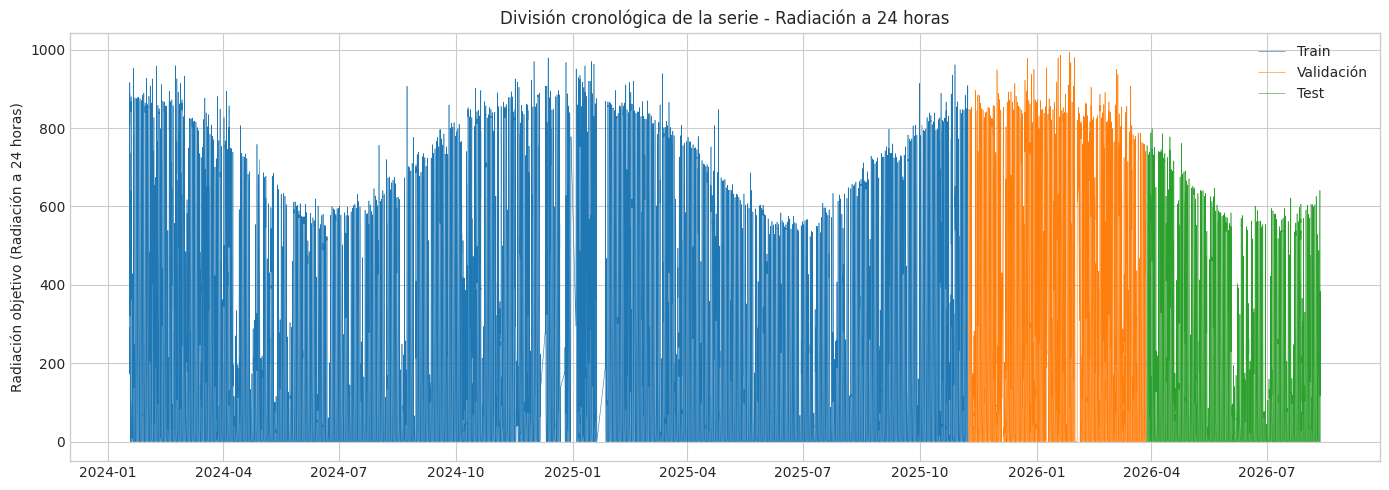

[24h] Filas diurnas -> train: 28419 | val (stop/blend): 3448 | val (ranking): 3448
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
[24h] Objetivo: kt_objetivo | Predictores: 70 | Con pronóstico NWP: True
AutoML progress: |
18:22:38.99: Project: radiacion_v3_24h
18:22:38.99: Cross-validation disabled by user: no fold column nor nfolds > 1.
18:22:38.100: Setting stopping tolerance adaptively based on the training frame: 0.005931924352264573
18:22:38.100: Build control seed: 42
18:22:38.100: training frame: Frame key: AutoML_3_20260927_182238_training_Key_Frame__upload_bc4b7c4475381be4e8e8a0ae11d74579.hex    cols: 73    rows: 28419  chunks: 6    size: 11240303  checksum: 6907764758328969534
18:22:38.100: validation frame: Frame key: Key_Frame__upload_ba6ec

/home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,model_id,rmse,mse,mae,rmsle,mean_residual_deviance
0,GLM_1_AutoML_3_20260927_182238,0.229023,0.052452,0.168622,0.160288,0.052452
1,GBM_2_AutoML_3_20260927_182238,0.232268,0.053948,0.164474,0.161756,0.053948
2,XRT_1_AutoML_3_20260927_182238,0.232353,0.053988,0.166946,0.162595,0.053988
3,GBM_grid_1_AutoML_3_20260927_182238_model_1,0.232898,0.054242,0.164581,0.162359,0.054242
4,GBM_4_AutoML_3_20260927_182238,0.233422,0.054486,0.164786,0.162644,0.054486
5,GBM_3_AutoML_3_20260927_182238,0.233813,0.054668,0.165997,0.162613,0.054668
6,GBM_1_AutoML_3_20260927_182238,0.235607,0.055511,0.168789,0.163961,0.055511
7,DRF_1_AutoML_3_20260927_182238,0.236534,0.055949,0.170039,0.165329,0.055949
8,GBM_5_AutoML_3_20260927_182238,0.236916,0.056129,0.167554,0.165150,0.056129
9,StackedEnsemble_BestOfFamily_1_AutoML_3_202609...,0.239770,0.057490,0.186879,0.162550,0.057490


[24h] Modelo ganador: GLM_1_AutoML_3_20260927_182238
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
[24h] Filas de test con pronóstico NWP: 100.0 %
[24h] Métricas en test (modelo vs. referencias):


/home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,MAE,RMSE,R2,MAPE_sin_ceros_pct,MAE_diurno,RMSE_diurno,MAE_max_diario,sesgo_max_diario,MAE_top10pct,sesgo_top10pct,skill_vs_climatologia
H2O_AutoML_v3,35.246,75.090,0.861,111.673,85.010,117.088,73.685,-24.714,65.985,-61.348,0.215
persistencia,49.778,118.844,0.651,135.884,120.927,185.685,96.005,-13.712,136.396,-120.601,-0.243
climatologia,50.799,95.637,0.774,148.180,122.965,148.851,143.209,-79.981,141.747,-141.719,0.000
pronostico_NWP_crudo,39.254,87.742,0.810,127.040,94.448,137.189,86.895,62.167,57.422,16.264,0.083


[24h] Skill score vs. climatología: +0.215 -> el modelo le gana a la climatología.


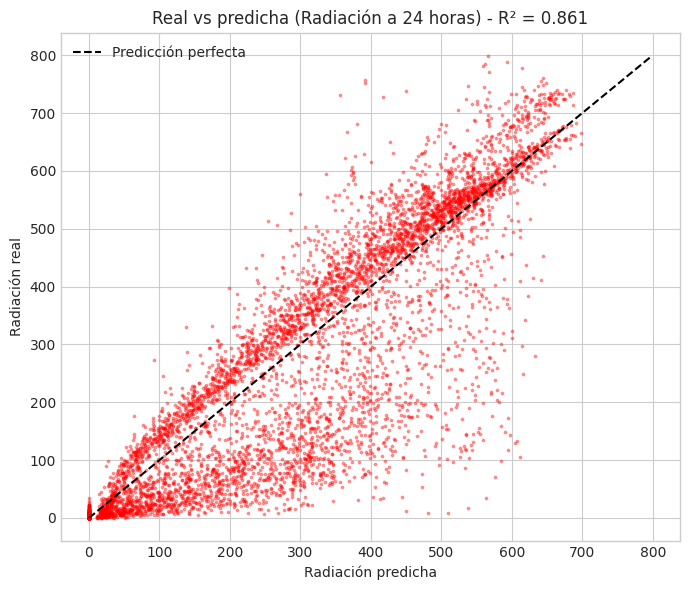

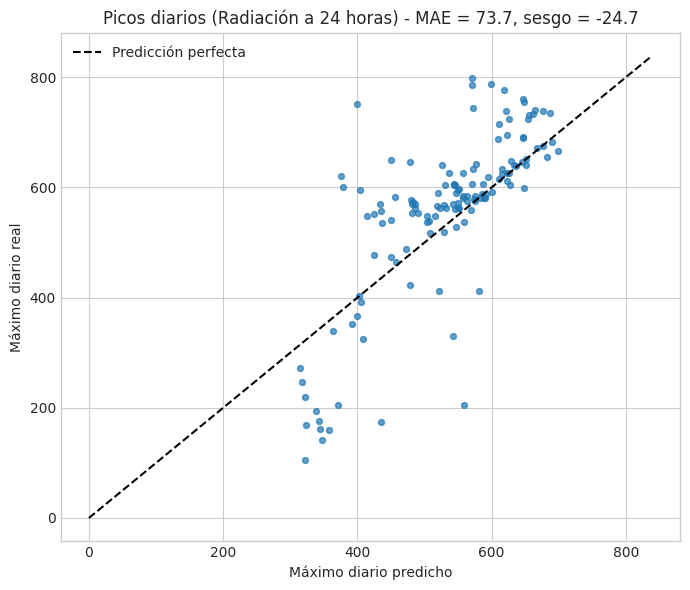

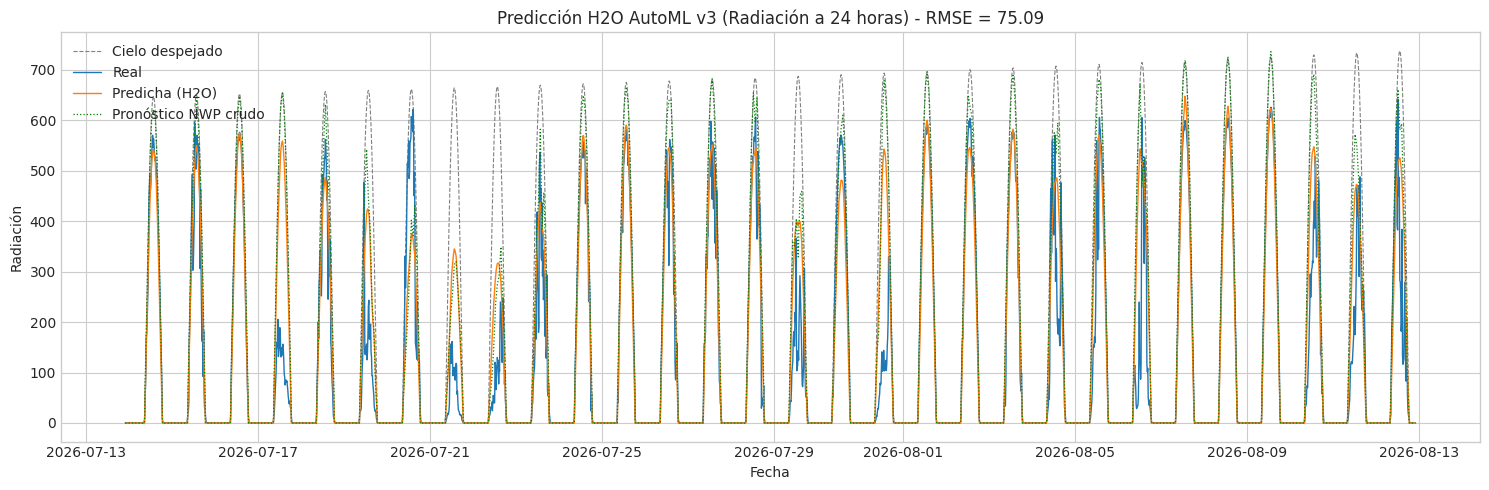

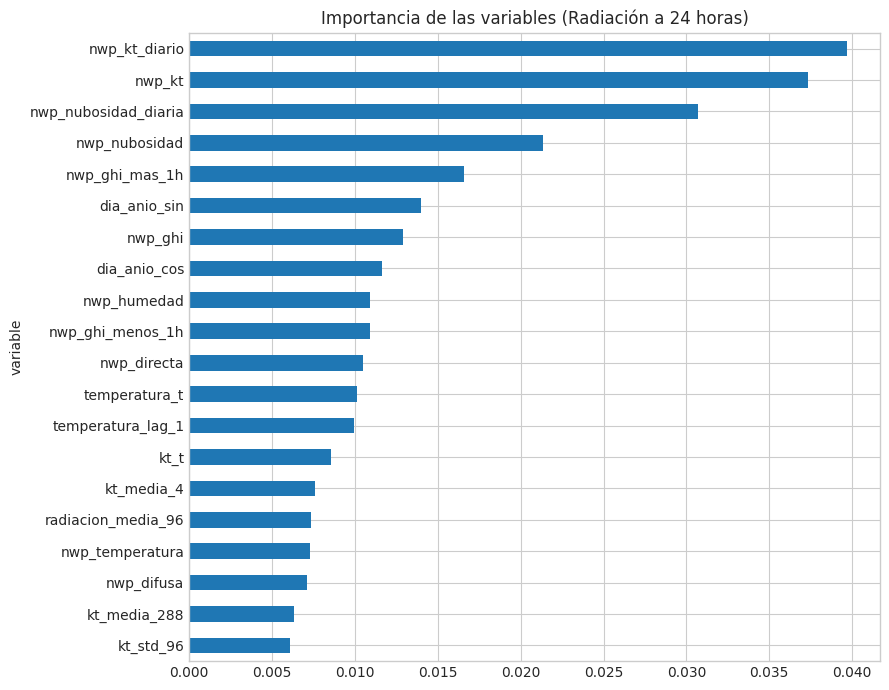

[24h] Modelo guardado en: /home/csosach/tp2/automl/resultados_h2o_radiacion_v3/24h/modelos/GLM_1_AutoML_3_20260927_182238


In [18]:
resultado_24h = entrenar_evaluar_horizonte(96, '24h', 'Radiación a 24 horas')

## 16. Ejecución — pronóstico a 1 semana

672 pasos de 15 minutos hacia adelante.

=== Horizonte: Radiación a 1 semana (672 pasos de 15 min) ===
[7d] Filas utilizables: 86788 | desde 2024-01-18 08:30:00 hasta 2026-08-05 22:15:00
[7d] Entrenamiento: (60751, 73) 2024-01-18 08:30:00 2025-11-03 17:00:00
[7d] Validación: (13018, 73) 2025-11-03 17:15:00 2026-03-23 03:45:00
[7d] Prueba: (13019, 73) 2026-03-23 04:00:00 2026-08-05 22:15:00


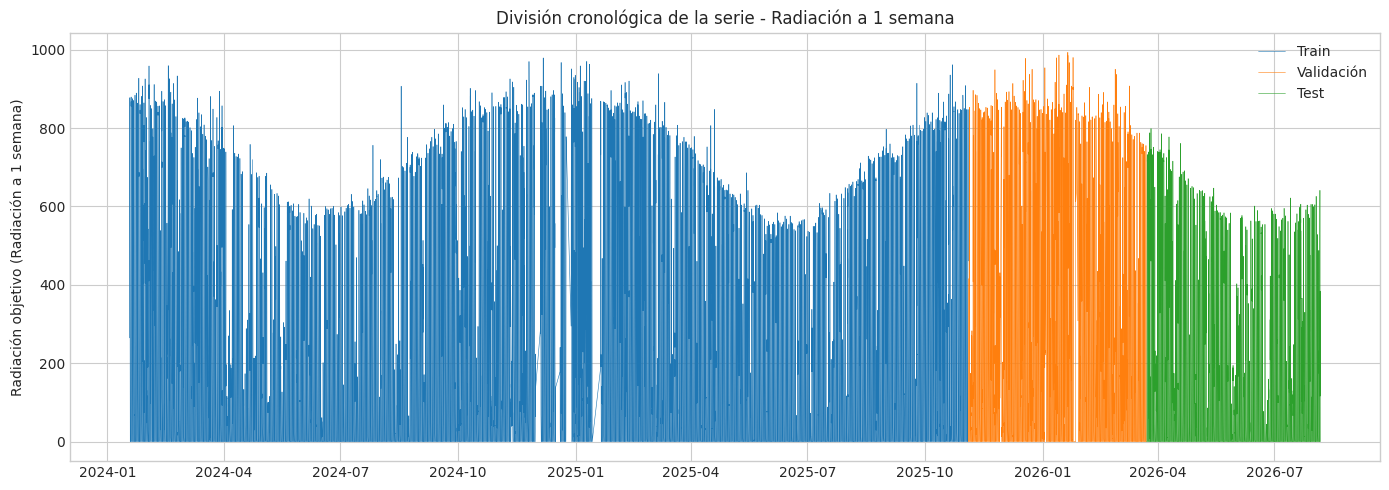

[7d] Filas diurnas -> train: 28199 | val (stop/blend): 3424 | val (ranking): 3425
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
[7d] Objetivo: kt_objetivo | Predictores: 70 | Con pronóstico NWP: True
AutoML progress: |
18:24:00.330: Project: radiacion_v3_7d
18:24:00.330: Cross-validation disabled by user: no fold column nor nfolds > 1.
18:24:00.331: Setting stopping tolerance adaptively based on the training frame: 0.0059550189281321825
18:24:00.331: Build control seed: 42
18:24:00.331: training frame: Frame key: AutoML_4_20260927_182400_training_Key_Frame__upload_b997cb2a460a9d279f7fb522168343ac.hex    cols: 73    rows: 28199  chunks: 6    size: 11189847  checksum: 8377004531382718078
18:24:00.331: validation frame: Frame key: Key_Frame__upload_80fda

/home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,model_id,rmse,mse,mae,rmsle,mean_residual_deviance
0,GLM_1_AutoML_4_20260927_182400,0.251042,0.063022,0.201068,0.174309,0.063022
1,GBM_5_AutoML_4_20260927_182400,0.257835,0.066479,0.209317,0.177601,0.066479
2,GBM_grid_1_AutoML_4_20260927_182400_model_1,0.258517,0.066831,0.199140,0.179322,0.066831
3,GBM_3_AutoML_4_20260927_182400,0.258681,0.066916,0.205604,0.177670,0.066916
4,DRF_1_AutoML_4_20260927_182400,0.258697,0.066924,0.204698,0.178905,0.066924
5,XRT_1_AutoML_4_20260927_182400,0.260540,0.067881,0.204630,0.180309,0.067881
6,GBM_2_AutoML_4_20260927_182400,0.263127,0.069236,0.206125,0.181889,0.069236
7,XGBoost_3_AutoML_4_20260927_182400,0.265249,0.070357,0.206711,0.182756,0.070357
8,GBM_1_AutoML_4_20260927_182400,0.265252,0.070359,0.203796,0.182724,0.070359
9,StackedEnsemble_BestOfFamily_1_AutoML_4_202609...,0.266259,0.070894,0.227606,0.180941,0.070894


[7d] Modelo ganador: GLM_1_AutoML_4_20260927_182400
Parse progress: |████████████████████████████████████████████████████████████████| (done) 100%
glm prediction progress: |███████████████████████████████████████████████████████| (done) 100%
[7d] Filas de test con pronóstico NWP: 100.0 %
[7d] Métricas en test (modelo vs. referencias):


/home/csosach/miniconda3/envs/mi_entorno/lib/python3.10/site-packages/h2o/frame.py:1983: H2ODependencyWarning: Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using multi-thread, install polars and pyarrow and use it as pandas_df = h2o_df.as_data_frame(use_multi_thread=True)

  warnings.warn("Converting H2O frame to pandas dataframe using single-thread.  For faster conversion using"


,MAE,RMSE,R2,MAPE_sin_ceros_pct,MAE_diurno,RMSE_diurno,MAE_max_diario,sesgo_max_diario,MAE_top10pct,sesgo_top10pct,skill_vs_climatologia
H2O_AutoML_v3,47.261,89.326,0.801,132.984,114.911,139.463,129.583,-77.515,132.246,-132.036,0.068
persistencia,65.276,141.803,0.498,206.815,158.966,222.378,134.367,-7.084,151.822,-125.392,-0.480
climatologia,50.774,95.799,0.771,149.387,123.108,149.232,142.688,-78.703,141.062,-141.029,0.000
pronostico_NWP_crudo,48.116,103.918,0.730,158.262,116.005,162.842,105.127,-17.466,113.844,-81.731,-0.085


[7d] Skill score vs. climatología: +0.068 -> el modelo le gana a la climatología.


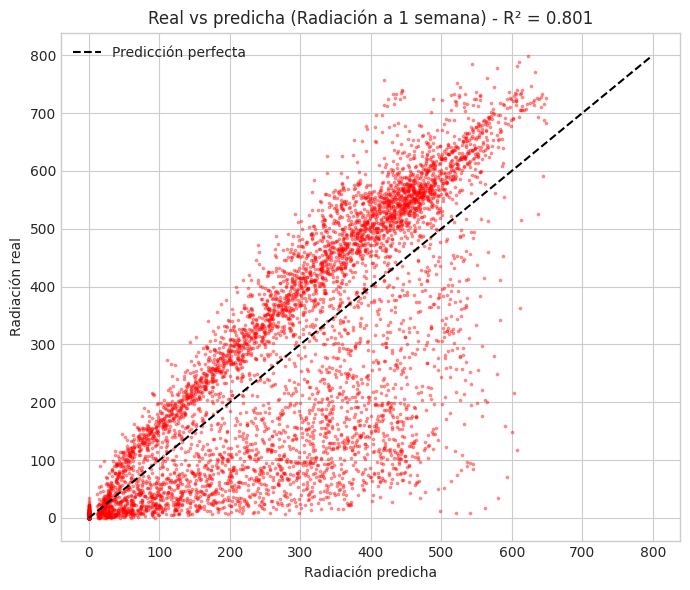

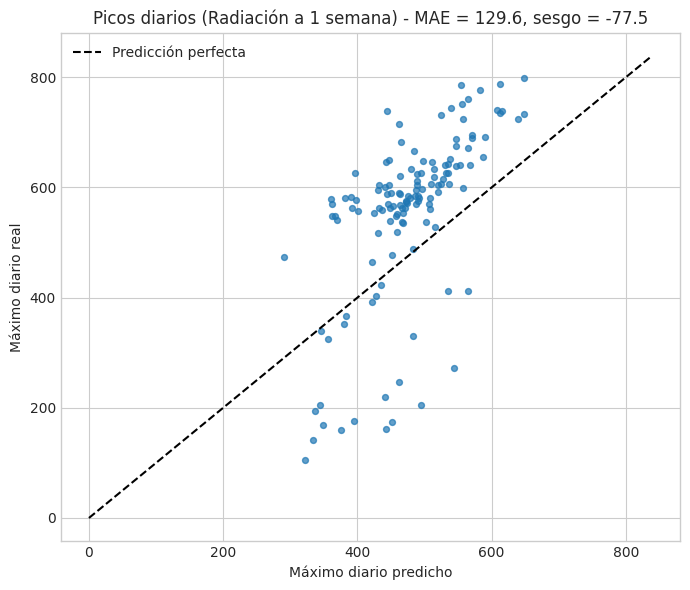

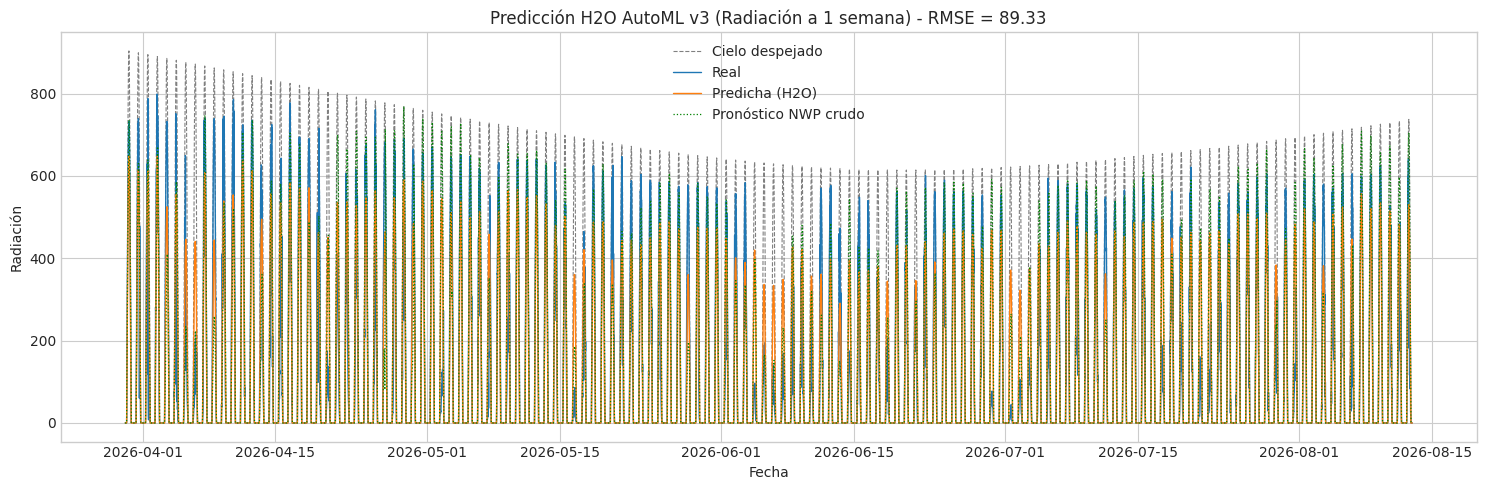

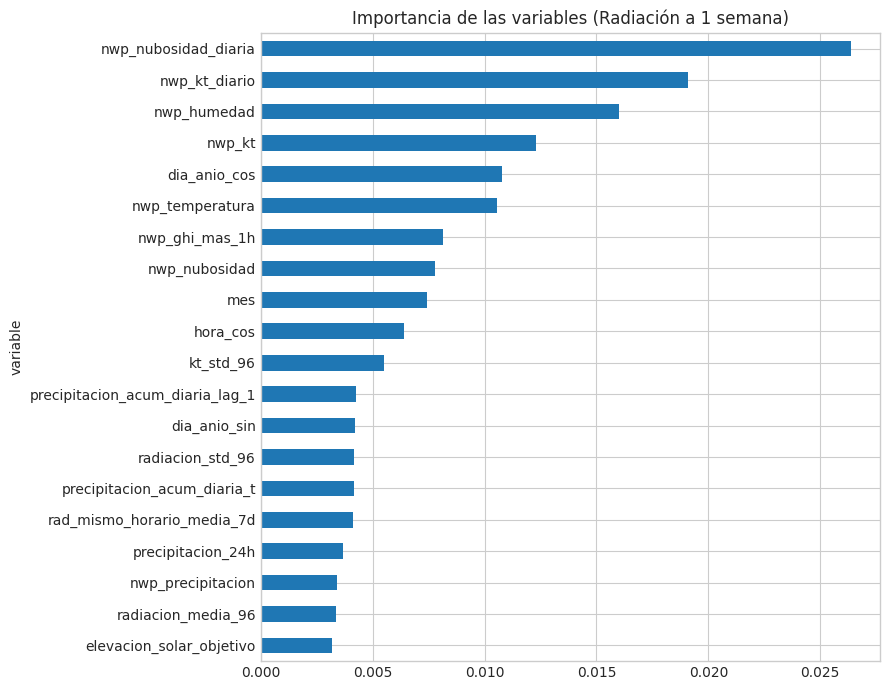

[7d] Modelo guardado en: /home/csosach/tp2/automl/resultados_h2o_radiacion_v3/7d/modelos/GLM_1_AutoML_4_20260927_182400


In [19]:
resultado_7d = entrenar_evaluar_horizonte(672, '7d', 'Radiación a 1 semana')

## 17. Comparación entre horizontes e interpretación

Cómo leer el *skill score* respecto de la climatología:

- **Cerca de 0 o negativo:** el modelo no aporta más que "un día típico de esta época". A 1 semana esto es lo esperable: la nubosidad de dentro de 7 días es prácticamente impredecible, incluso para los modelos meteorológicos.
- **Positivo:** el modelo le gana a la climatología. A 1 semana, **cualquier valor positivo ya es un buen resultado**.
- A 24 h, con pronóstico meteorológico, es razonable esperar un skill claramente positivo y que el modelo también supere al **pronóstico NWP crudo** (es decir, que corrija sus sesgos locales).

In [20]:
tabla_comparativa = pd.DataFrame([resultado_24h, resultado_7d]).set_index('horizonte')
tabla_comparativa.to_csv(os.path.join(BASE_RESULTADOS, 'comparacion_horizontes.csv'))

for h, fila in tabla_comparativa.iterrows():
    veredicto = 'le gana a la climatología' if fila['skill_vs_climatologia'] > 0 else 'no supera a la climatología'
    print(f"{h}: RMSE = {fila['RMSE']:.2f} | skill vs. climatología = {fila['skill_vs_climatologia']:+.3f} -> {veredicto}")

tabla_comparativa

24h: RMSE = 75.09 | skill vs. climatología = +0.215 -> le gana a la climatología
7d: RMSE = 89.33 | skill vs. climatología = +0.068 -> le gana a la climatología


,pasos_15min,modelo_ganador,con_pronostico_NWP,cielo_despejado,modo_automl,MAE,RMSE,R2,MAPE_sin_ceros_pct,MAE_diurno,RMSE_diurno,MAE_max_diario,sesgo_max_diario,MAE_top10pct,sesgo_top10pct,skill_vs_climatologia
horizonte,,,,,,,,,,,,,,,,
24h,96,GLM_1_AutoML_3_20260927_182238,True,teorico,rapido,35.246183,75.090005,0.860501,111.673136,85.009766,117.088479,73.684914,-24.713720,65.985079,-61.348179,0.214840
7d,672,GLM_1_AutoML_4_20260927_182400,True,teorico,rapido,47.261406,89.326088,0.800695,132.983848,114.910865,139.462670,129.583014,-77.514816,132.245772,-132.036155,0.067564


## 18. Comparación con las versiones anteriores (opcional)

Si en la misma carpeta están los resultados de la v1 (`resultados_h2o_radiacion/`) y de la v2 (`resultados_h2o_radiacion_v2/`), esta celda los reúne en una tabla. Nota: la v3 puede evaluar en un período de prueba algo distinto si se recortó la serie a la cobertura del pronóstico.

In [21]:
filas = []
for version, carpeta in [('v1', 'resultados_h2o_radiacion'), ('v2', 'resultados_h2o_radiacion_v2'), ('v3', 'resultados_h2o_radiacion_v3')]:
    for h in ['24h', '7d']:
        ruta = os.path.join(carpeta, h, 'metricas', 'metricas.csv')
        if os.path.exists(ruta):
            m = pd.read_csv(ruta, index_col=0)
            fila = m.iloc[0]   # la primera fila es siempre el modelo H2O
            filas.append({'version': version, 'horizonte': h, **{k: fila[k] for k in ['MAE', 'RMSE', 'R2'] if k in fila},
                          **{k: fila[k] for k in ['MAE_max_diario', 'sesgo_max_diario', 'skill_vs_climatologia'] if k in fila}})
pd.DataFrame(filas).set_index(['horizonte', 'version']).sort_index() if filas else print('No se encontraron resultados previos.')

MAE        RMSE        R2  MAE_max_diario  \
horizonte version                                                    
24h       v1       49.578125  101.563121  0.833694             NaN   
          v2       50.969926  102.913193  0.832247      121.288863   
          v3       35.246183   75.090005  0.860501       73.684914   
7d        v1       53.479648  107.219463  0.815424             NaN   
          v2       54.662045  107.563368  0.816501      121.020331   
          v3       47.261406   89.326088  0.800695      129.583014   

                   sesgo_max_diario  skill_vs_climatologia  
horizonte version                                           
24h       v1                    NaN                    NaN  
          v2             -77.481953                    NaN  
          v3             -24.713720               0.214840  
7d        v1                    NaN                    NaN  
          v2             -65.828920                    NaN  
          v3             -77.514816               0.067564

## 19. Cierre de H2O
Ejecutar esta celda cuando ya no se utilizará el clúster H2O.

In [22]:
h2o.cluster().shutdown(prompt=False)

H2O session _sid_80c2 closed.
